In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.describe

<bound method NDFrame.describe of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
print(df.duplicated().sum())

0


In [8]:
df = df.drop_duplicates()

In [9]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns

print("Numerical Columns:")
print(num_cols)
num_cols = num_cols.drop(["Survived"])

print("\nCategorical Columns:")
print(cat_cols)

Numerical Columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

Categorical Columns:
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


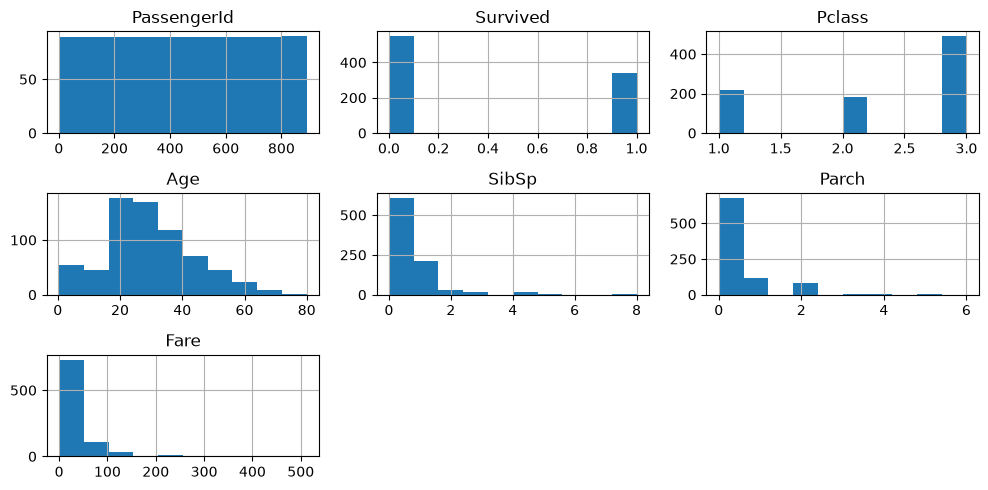

In [10]:
df.hist(figsize=(10,5))
plt.tight_layout()
plt.show()
 

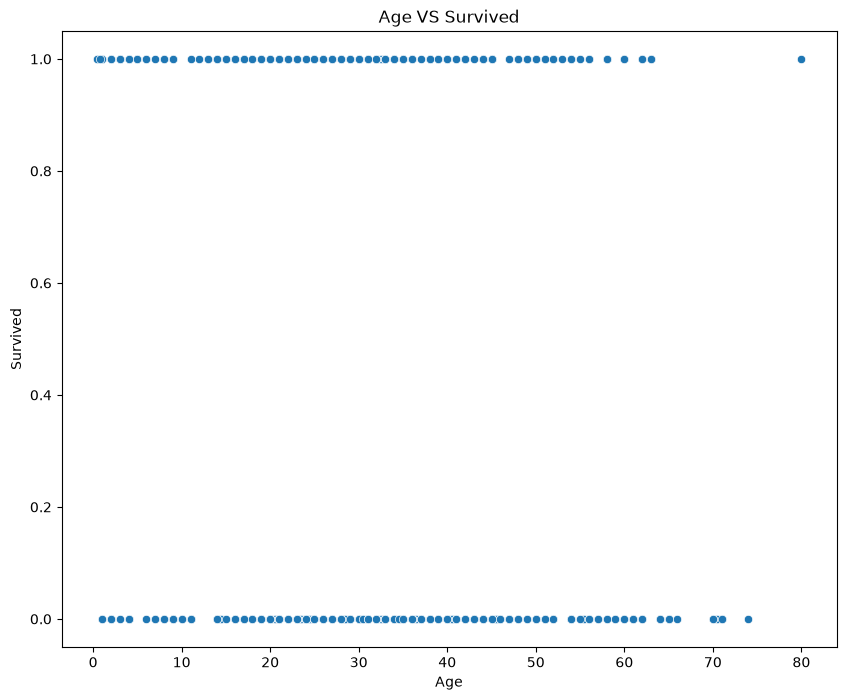

In [11]:
plt.figure(figsize = (10,8))
sns.scatterplot(
    data = df,
    x = "Age",
    y = "Survived"
)

plt.title("Age VS Survived")
plt.show()

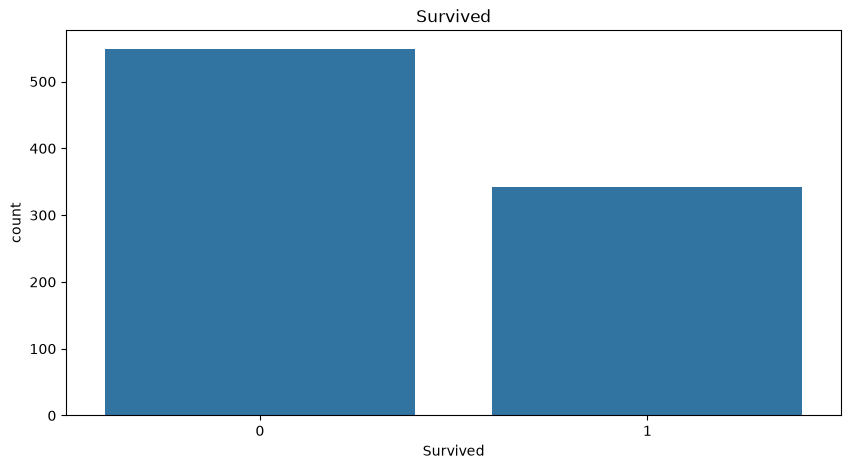

In [12]:
plt.figure(figsize=(10,5))
sns.countplot(
    data = df,
    x = "Survived"
)
plt.title("Survived")
plt.show()

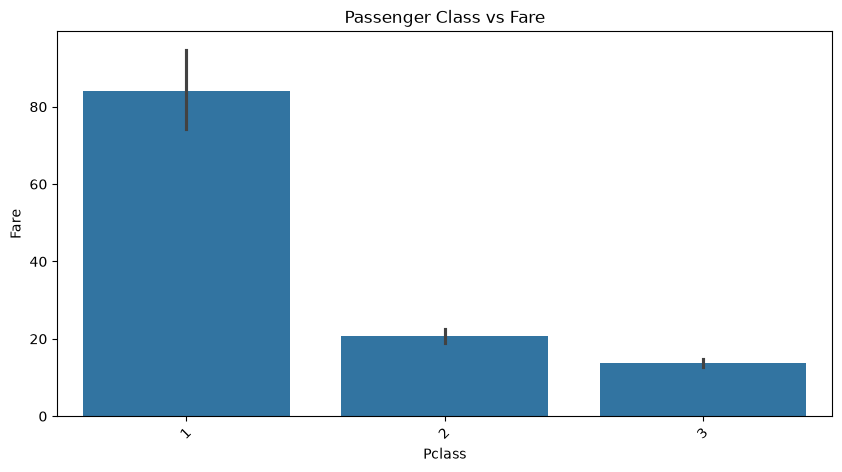

In [13]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df, 
    x="Pclass", 
    y="Fare"
)
plt.xticks(rotation = 45)
plt.title("Passenger Class vs Fare")
plt.show()

In [14]:
corr = df[num_cols].corr()
corr

,PassengerId,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Pclass,-0.035144,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,-0.549500,0.096067,0.159651,0.216225,1.000000


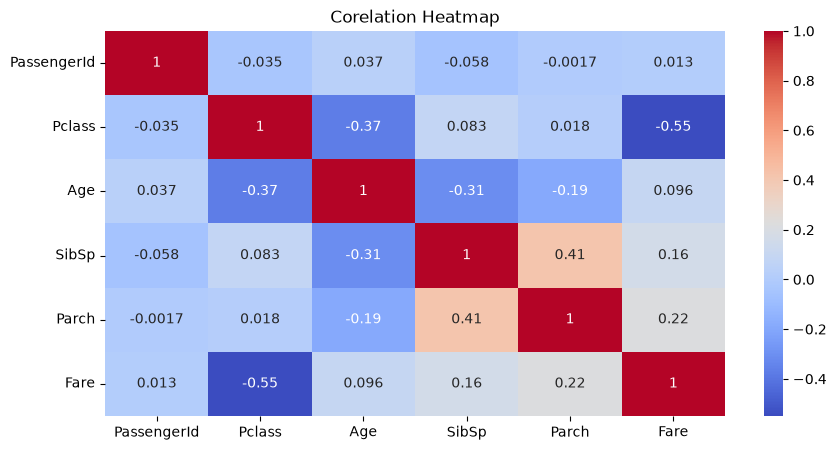

In [15]:
plt.figure(figsize = (10,5))
sns.heatmap(
    corr,
    annot=True,
    cmap = "coolwarm"
)

plt.title("Corelation Heatmap")
plt.show()

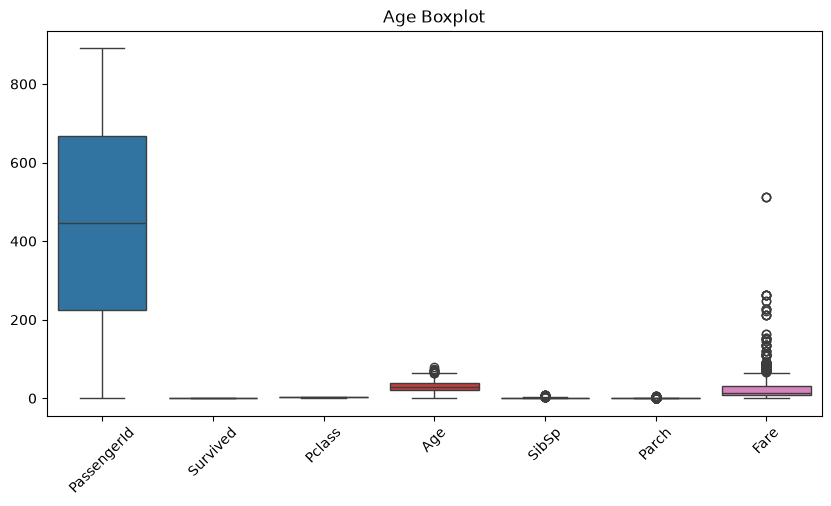

In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df)
plt.xticks(rotation = 45)
plt.title("Age Boxplot")
plt.show()

In [17]:
X = df.drop(["Survived"],axis = 1)
y = df["Survived"]

In [18]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [19]:
le = LabelEncoder()
y_enc = le.fit_transform(y)


In [20]:
print(y)

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64


In [21]:
print(le.classes_)

[0 1]


In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 11)
(179, 11)
(712,)
(179,)


In [24]:
cat_impute = SimpleImputer(strategy = "most_frequent")
num_impute = SimpleImputer(strategy = "median")

X_train[cat_cols] = cat_impute.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_impute.transform(X_test[cat_cols])

X_train[num_cols] = num_impute.fit_transform(X_train[num_cols])
X_test[num_cols] = num_impute.transform(X_test[num_cols])

In [25]:
enc = OneHotEncoder(handle_unknown = "ignore", sparse_output = False)
train_cat = enc.fit_transform(X_train[cat_cols])
test_cat = enc.transform(X_test[cat_cols])

In [26]:
scal = StandardScaler()

train_num = scal.fit_transform(X_train[num_cols])
test_num = scal.transform(X_test[num_cols])

In [27]:
X_train_scaled = np.hstack((train_num,train_cat))
X_test_scaled = np.hstack((test_num,test_cat))

In [28]:
print("Null values in trainig : ",np.isnan(X_train_scaled).sum())
print("Null values in test : ",np.isnan(X_test_scaled).sum())

Null values in trainig :  0
Null values in test :  0


In [29]:
from sklearn.linear_model import LinearRegression

In [30]:
linear = LinearRegression()
linear.fit(X_train_scaled,y_train)

LinearRegression()

In [31]:
y_pred = linear.predict(X_test_scaled)
print("Actual values : ",y_test[:5])
print("Predicted values :", y_pred[:5])

Actual values :  709    1
439    0
840    0
720    1
39     1
Name: Survived, dtype: int64
Predicted values : [0.16484163 0.20744603 0.15961974 0.83413437 1.07059106]


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [33]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MSE: 0.12029255265621829
MAE: 0.2726072594177898
R2 Score: 0.5039519073799369


In [34]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

In [35]:
ridge = Ridge()

ridge_params = {
    'alpha' : [0.001,0.01,0.1,1,10]
}

ridge_grid = GridSearchCV(
    ridge,
    ridge_params,
    cv = 5,
    scoring = "r2"
)

ridge_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10]}, scoring='r2')

In [36]:
ridge_best = ridge_grid.best_estimator_
y_pred_ridge = ridge_best.predict(X_test_scaled)

In [37]:
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("R2 Score:", r2_score(y_test, y_pred_ridge))

MSE: 0.12119912600289844
MAE: 0.27342625356006534
R2 Score: 0.5002134882549718


In [38]:
lasso = Lasso()

lasso_params = {
    'alpha' : [0.01,0.1,1,100]
}

lasso_grid = GridSearchCV(
    lasso,
    lasso_params,
    cv = 5,
    scoring = "r2"
)

lasso_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=Lasso(), param_grid={'alpha': [0.01, 0.1, 1, 100]},
             scoring='r2')

In [39]:
lasso_best = lasso_grid.best_estimator_
y_pred_lasso = lasso_best.predict(X_test_scaled)

In [40]:
print("MSE:", mean_squared_error(y_test, y_pred_lasso))
print("MAE:", mean_absolute_error(y_test, y_pred_lasso))
print("R2 Score:", r2_score(y_test, y_pred_lasso))

MSE: 0.13715717468944522
MAE: 0.3008312086939498
R2 Score: 0.4344075889028939


In [41]:
elastic = ElasticNet()

elastic_params = {
    'alpha' : [0.001,0.01,0.1,1,100],
    'l1_ratio' : [0.2,0.5,0.8]
}

elastic_grid = GridSearchCV(
    elastic,
    elastic_params,
    cv = 5,
    scoring = "r2"
) 

elastic_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=ElasticNet(),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 100],
                         'l1_ratio': [0.2, 0.5, 0.8]},
             scoring='r2')

In [42]:
elastic_best = elastic_grid.best_estimator_
y_pred_elastic = elastic_best.predict(X_test_scaled)

In [43]:
print("MSE:", mean_squared_error(y_test, y_pred_elastic))
print("MAE:", mean_absolute_error(y_test, y_pred_elastic))
print("R2 Score:", r2_score(y_test, y_pred_elastic))

MSE: 0.13307666454804465
MAE: 0.2858812607325345
R2 Score: 0.45123431032382255


In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score

In [45]:
log = LogisticRegression()

log_params = {
    'C' : [0.001,0.01,0.1,1,100],
    'solver' : ['liblinear','lbfgs']
}

log_grid = GridSearchCV(
    log,
    log_params,
    cv = 5,
    scoring = "accuracy"
)

log_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(),
             param_grid={'C': [0.001, 0.01, 0.1, 1, 100],
                         'solver': ['liblinear', 'lbfgs']},
             scoring='accuracy')

In [46]:
log_best = log_grid.best_estimator_
y_pred_log = log_best.predict(X_test_scaled)

In [47]:
from sklearn.metrics import classification_report

In [48]:
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log))

Accuracy: 0.8324022346368715
              precision    recall  f1-score   support

           0       0.84      0.89      0.86       105
           1       0.82      0.76      0.79        74

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



In [49]:
table_reg = pd.DataFrame({
    'Model' : ['Linear','Ridge','Lasso','ElasticNet'],
    'MAE' : [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_lasso),
        mean_absolute_error(y_test, y_pred_elastic)
    ],
    'MSE' : [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_elastic)
    ],
    'R2 Score' : [
        r2_score(y_test, y_pred),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_elastic)
    ]
})

table_reg

,Model,MAE,MSE,R2 Score
0,Linear,0.272607,0.120293,0.503952
1,Ridge,0.273426,0.121199,0.500213
2,Lasso,0.300831,0.137157,0.434408
3,ElasticNet,0.285881,0.133077,0.451234


In [50]:
from sklearn.svm import SVC

In [51]:
param_linear = {
    'C' : [0.01,0.1,1,10]
}

linear_svm_grid = GridSearchCV(
    SVC(kernel = 'linear'),
    param_linear,
    cv = 5,
    scoring = "accuracy"
)

linear_svm_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=SVC(kernel='linear'),
             param_grid={'C': [0.01, 0.1, 1, 10]}, scoring='accuracy')

In [52]:
linear_svm_best = linear_svm_grid.best_estimator_
y_pred_svm_linear = linear_svm_best.predict(X_test_scaled)

In [53]:
print("Accuracy : ",accuracy_score(y_test,y_pred_svm_linear))
print("Precision : ",precision_score(y_test,y_pred_svm_linear,pos_label = 1))
print("Recall : ",recall_score(y_test,y_pred_svm_linear,pos_label = 1))
print("F1 score : ",f1_score(y_test,y_pred_svm_linear,pos_label = 1))

Accuracy :  0.8379888268156425
Precision :  0.835820895522388
Recall :  0.7567567567567568
F1 score :  0.7943262411347518


In [54]:
print("hi")

hi


In [55]:
param_polynomial = {
    'C': [0.1, 1, 10],
    'degree': [2, 3],
    'gamma': ['scale', 'auto']
}

polynomial_svm_grid = GridSearchCV(
    SVC(kernel='poly'),
    param_polynomial,
    cv=3,
    scoring='accuracy'
)

polynomial_svm_grid.fit(X_train_scaled, y_train)


GridSearchCV(cv=3, estimator=SVC(kernel='poly'),
             param_grid={'C': [0.1, 1, 10], 'degree': [2, 3],
                         'gamma': ['scale', 'auto']},
             scoring='accuracy')

In [56]:
poly_svm_best = polynomial_svm_grid.best_estimator_
y_pred_svm_poly = poly_svm_best.predict(X_test_scaled)

In [57]:
print("Accuracy : ",accuracy_score(y_test,y_pred_svm_poly))
print("Precision : ",precision_score(y_test,y_pred_svm_poly,pos_label = 1))
print("Recall : ",recall_score(y_test,y_pred_svm_poly,pos_label = 1))
print("F1 score : ",f1_score(y_test,y_pred_svm_poly,pos_label = 1))
print("Best parameters : ",polynomial_svm_grid.best_params_)
print("Best CV score : ",polynomial_svm_grid.best_score_)

Accuracy :  0.8324022346368715
Precision :  0.84375
Recall :  0.7297297297297297
F1 score :  0.782608695652174
Best parameters :  {'C': 10, 'degree': 2, 'gamma': 'scale'}
Best CV score :  0.8244749376543866


In [58]:
param_sigmoid = {
    'C' : [0.01,0.1,1],
    'gamma':['scale','auto',0.01,0.1]
}

sigmoid_svm_grid = GridSearchCV(
    SVC(kernel = 'sigmoid'),
    param_sigmoid,
    cv = 5,
    scoring = "accuracy"
)

sigmoid_svm_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=SVC(kernel='sigmoid'),
             param_grid={'C': [0.01, 0.1, 1],
                         'gamma': ['scale', 'auto', 0.01, 0.1]},
             scoring='accuracy')

In [59]:
sigmoid_svm_best = sigmoid_svm_grid.best_estimator_
y_pred_svm_sigmoid = sigmoid_svm_best.predict(X_test_scaled)

In [60]:
print("Accuracy : ",accuracy_score(y_test,y_pred_svm_sigmoid))
print("Precision : ",precision_score(y_test,y_pred_svm_sigmoid,pos_label = 1))
print("Recall : ",recall_score(y_test,y_pred_svm_sigmoid,pos_label = 1))
print("F1 score : ",f1_score(y_test,y_pred_svm_sigmoid,pos_label = 1))

Accuracy :  0.7821229050279329
Precision :  0.7536231884057971
Recall :  0.7027027027027027
F1 score :  0.7272727272727273


In [61]:
param_rbf = {
    'C' : [0.01,0.1],
    'gamma' : ['scale','auto',0.1,]
}

rbf_svm_grid = GridSearchCV(
    SVC(kernel = 'rbf'),
    param_rbf,
    cv  = 5,
    scoring = 'accuracy'
)

rbf_svm_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.01, 0.1], 'gamma': ['scale', 'auto', 0.1]},
             scoring='accuracy')

In [62]:
from sklearn.linear_model import Perceptron

In [63]:
per = Perceptron()

params = {
    'max_iter' : [500,1000],
    'eta0' : [0.1,1]
}

per_grid = GridSearchCV(
    per,
    params,
    cv = 5,
    scoring = "accuracy",
    n_jobs = -1
)

per_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=Perceptron(), n_jobs=-1,
             param_grid={'eta0': [0.1, 1], 'max_iter': [500, 1000]},
             scoring='accuracy')

In [64]:
per_best = per_grid.best_estimator_
y_pred_per = per_best.predict(X_test_scaled)

In [65]:
print("Accuracy : ",accuracy_score(y_test,y_pred_per))
print("Precision : ",precision_score(y_test,y_pred_per,pos_label = 1))
print("Recall : ",recall_score(y_test,y_pred_per,pos_label = 1))
print("F1 score : ",f1_score(y_test,y_pred_per,pos_label = 1))

Accuracy :  0.8212290502793296
Precision :  0.8181818181818182
Recall :  0.7297297297297297
F1 score :  0.7714285714285715


In [66]:
from sklearn.neural_network import MLPClassifier

In [67]:
print("hi")

hi


In [68]:
print("hi")

hi


In [69]:
mlp = MLPClassifier(
    random_state=42,
    max_iter=200,
    early_stopping=True
)

mlp_param = {
    'hidden_layer_sizes': [(50,), (100,)],
    'activation': ['relu'],
    'solver': ['adam'],
    'learning_rate_init': [0.001],
    'batch_size': [32],
    'max_iter': [200]
}

mlp_grid = GridSearchCV(
    mlp, mlp_param,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

mlp_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", mlp_grid.best_params_)
print("Best Accuracy:", mlp_grid.best_score_)

Best Parameters: {'activation': 'relu', 'batch_size': 32, 'hidden_layer_sizes': (100,), 'learning_rate_init': 0.001, 'max_iter': 200, 'solver': 'adam'}
Best Accuracy: 0.8061849212258743


In [70]:
from sklearn.neighbors import KNeighborsClassifier

In [71]:
knn = KNeighborsClassifier()

knn_params = {
    'n_neighbors' : [3,5,7],
    'weights' : ['uniform','distance'],
    'metric' : ['euclidean','manhattan']
}

knn_grid = GridSearchCV(
    knn,
    knn_params,
    cv = 3,
    scoring = "accuracy",
    n_jobs = -1
)

knn_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=3, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'metric': ['euclidean', 'manhattan'],
                         'n_neighbors': [3, 5, 7],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [72]:
knn_grid_best = knn_grid.best_estimator_
y_pred_knn = knn_grid_best.predict(X_test_scaled)

In [73]:
print("Accuracy : ",accuracy_score(y_test,y_pred_knn))
print("Precision : ",precision_score(y_test,y_pred_knn,pos_label = 1))
print("Recall : ",recall_score(y_test,y_pred_knn,pos_label = 1))
print("F1 score : ",f1_score(y_test,y_pred_knn,pos_label = 1))

Accuracy :  0.8435754189944135
Precision :  0.859375
Recall :  0.7432432432432432
F1 score :  0.7971014492753623


In [74]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

In [75]:
bag = BaggingClassifier(
    estimator = DecisionTreeClassifier(),
    random_state = 42
)

bag_params = {
    'n_estimators' : [5,10,20],
    'max_samples' : [0.5,0.7,1],
    'max_features' : [0.5,0.7,1]
}

bag_grid = GridSearchCV(
    bag,
    bag_params,
    cv = 3,
    scoring = "accuracy",
    n_jobs = -1
)

bag_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=3,
             estimator=BaggingClassifier(estimator=DecisionTreeClassifier(),
                                         random_state=42),
             n_jobs=-1,
             param_grid={'max_features': [0.5, 0.7, 1],
                         'max_samples': [0.5, 0.7, 1],
                         'n_estimators': [5, 10, 20]},
             scoring='accuracy')

In [76]:
from sklearn.ensemble import AdaBoostClassifier 

In [77]:
ada = AdaBoostClassifier()

ada_params = {
    'n_estimators' : [5,10,20],
    'learning_rate' : [0.01,0.1],
}

ada_grid = GridSearchCV(
    ada,
    ada_params,
    cv = 3,
    scoring = 'accuracy',
    n_jobs = -1
)

ada_grid.fit(X_train_scaled,y_train)

C:\Users\arivu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


GridSearchCV(cv=3, estimator=AdaBoostClassifier(), n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1],
                         'n_estimators': [5, 10, 20]},
             scoring='accuracy')

In [78]:
from sklearn.ensemble import GradientBoostingClassifier 

In [79]:
gradient = GradientBoostingClassifier()

gradient_params = {
    'n_estimators' : [5,10,20],
    'learning_rate' : [0.01,0.1],
    'max_depth' : [2,3]
}

gradient_grid = GridSearchCV(
    gradient,
    gradient_params,
    cv = 3,
    scoring = 'accuracy',
    n_jobs = -1
)

gradient_grid.fit(X_train_scaled,y_train)

GridSearchCV(cv=3, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1], 'max_depth': [2, 3],
                         'n_estimators': [5, 10, 20]},
             scoring='accuracy')

In [80]:
from sklearn.ensemble import StackingClassifier

In [ ]:
estimators = [
    ('lr',LogisticRegression(max_iter = 200)),
    ('dt',DecisionTreeClassifier(random_state = 42)),
    ('svm',SVC(probability = True))
]

stack = StackingClassifier(
    estimators = estimators,
    final_estimator = LogisticRegression(max_iter = 200),
    cv = 3
)

stack_params = {
    'final_estimator__C': [0.1,1,10],
    'dt__max_depth' : [None,5,7]
}

stack_grid = GridSearchCV(
    stack,
    stack_params,
    cv = 3,
    scoring = "f1_weighted",
    n_jobs = -1
)

stack_grid.fit(X_train_scaled,y_train)


In [ ]:
from sklearn.tree import plot_tree

au= stack_grid.best_estimator_
dt = au.named_estimators_["dt"]

plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    feature_names=None,
    class_names=["Not Survived", "Survived"],
    filled=True,
    max_depth=3
)
plt.title("Decision Tree Used in Stacking Classifier")
plt.show()

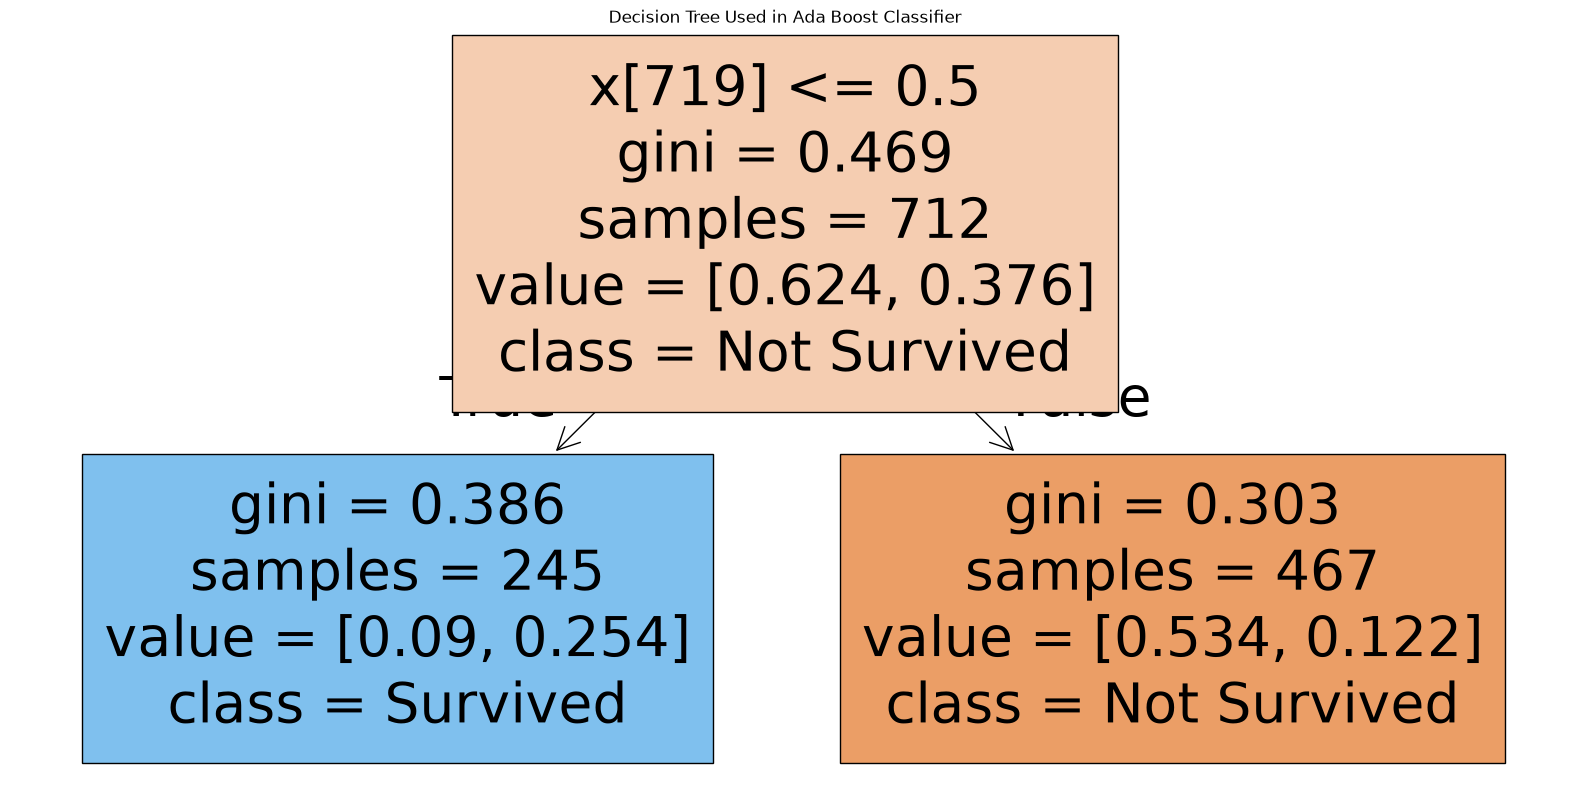

In [114]:
from sklearn.tree import plot_tree

ada = ada_grid.best_estimator_
dt = ada.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    feature_names=None,
    class_names=["Not Survived", "Survived"],
    filled=True,
    max_depth=3
)
plt.title("Decision Tree Used in Ada Boost Classifier")
plt.show()

In [100]:
decision = DecisionTreeClassifier(
    random_state = 42
)

decision_params = {
    'max_depth' : [3,5,None],
    'criterion' : ['gini','entropy'],
    'min_samples_split' : [2,5,8]
}

dec_grid = GridSearchCV(
    decision,
    decision_params,
    cv = 3,
    scoring = "accuracy",
    n_jobs = -1
)

dec_grid.fit(X_train_scaled,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Accuracy: 0.8212290502793296
Precision: 0.828125
Recall: 0.7162162162162162
F1 Score: 0.7681159420289855


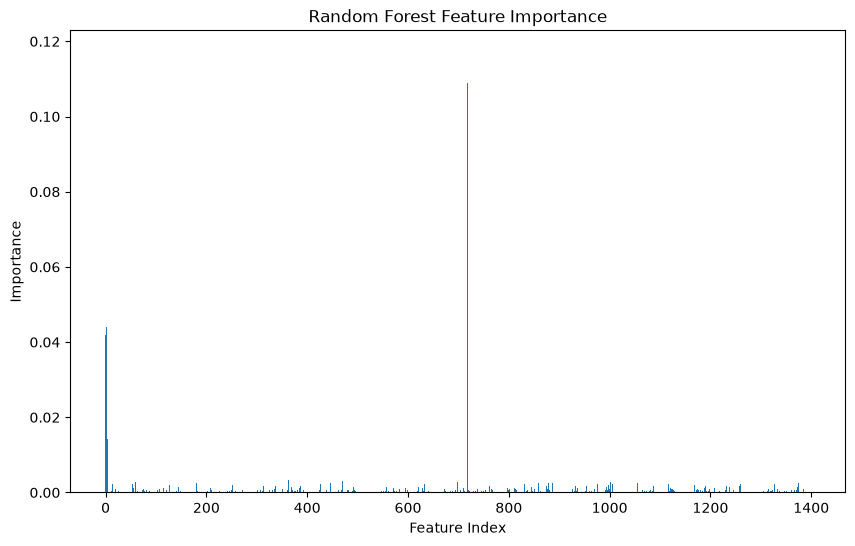

In [101]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        "n_estimators": [50, 100],
        "max_depth": [5, 10, None],
        "min_samples_split": [2, 5]
    },
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

rf = rf_grid.best_estimator_
y_pred = rf.predict(X_test_scaled)

print("Best Parameters:", rf_grid.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

plt.figure(figsize=(10, 6))
plt.bar(range(len(rf.feature_importances_)), rf.feature_importances_)
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.show()

In [102]:
bag_rf = BaggingClassifier(
    estimator=RandomForestClassifier(random_state=42),
    random_state=42
)

bag_rf_params = {
    'n_estimators': [5, 10],
    'max_samples': [0.7, 1.0]
}

grid = GridSearchCV(bag_rf, bag_rf_params, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

y_pred = grid.best_estimator_.predict(X_test_scaled)

print("Best Parameters:", grid.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))

print(pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred}).head())

Best Parameters: {'max_samples': 0.7, 'n_estimators': 5}
Accuracy: 0.7988826815642458
Precision: 0.7987081005586593
Recall: 0.7988826815642458
F1 Score: 0.7961666703468986
   Actual  Predicted
0       1          0
1       0          0
2       0          0
3       1          1
4       1          1


In [103]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model = AdaBoostClassifier(
    estimator=RandomForestClassifier(
        n_estimators=10, random_state=42
    ),
    random_state=42
)

params = {
    'n_estimators': [5, 10],
    'learning_rate': [0.1, 1.0]
}

grid = GridSearchCV(model, params, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

y_pred = grid.best_estimator_.predict(X_test_scaled)

print("Best Parameters:", grid.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))

print(pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred}).head())

Best Parameters: {'learning_rate': 1.0, 'n_estimators': 5}
Accuracy: 0.8044692737430168
Precision: 0.8034756111025241
Recall: 0.8044692737430168
F1 Score: 0.8033245174988711
   Actual  Predicted
0       1          0
1       0          0
2       0          0
3       1          1
4       1          1


In [108]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_model = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(random_state=42)),
        ('svm', SVC(probability=True, random_state=42))
    ],
    final_estimator=LogisticRegression(max_iter=1000)
)

rf_params = {
    'rf__n_estimators': [50, 100],
    'rf__max_depth': [None, 10],
    'final_estimator__C': [0.1, 1, 10]
}

rf_rid = GridSearchCV(rf_model, rf_params, cv=3, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'min_samples_split': [2, 5], 'n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls 

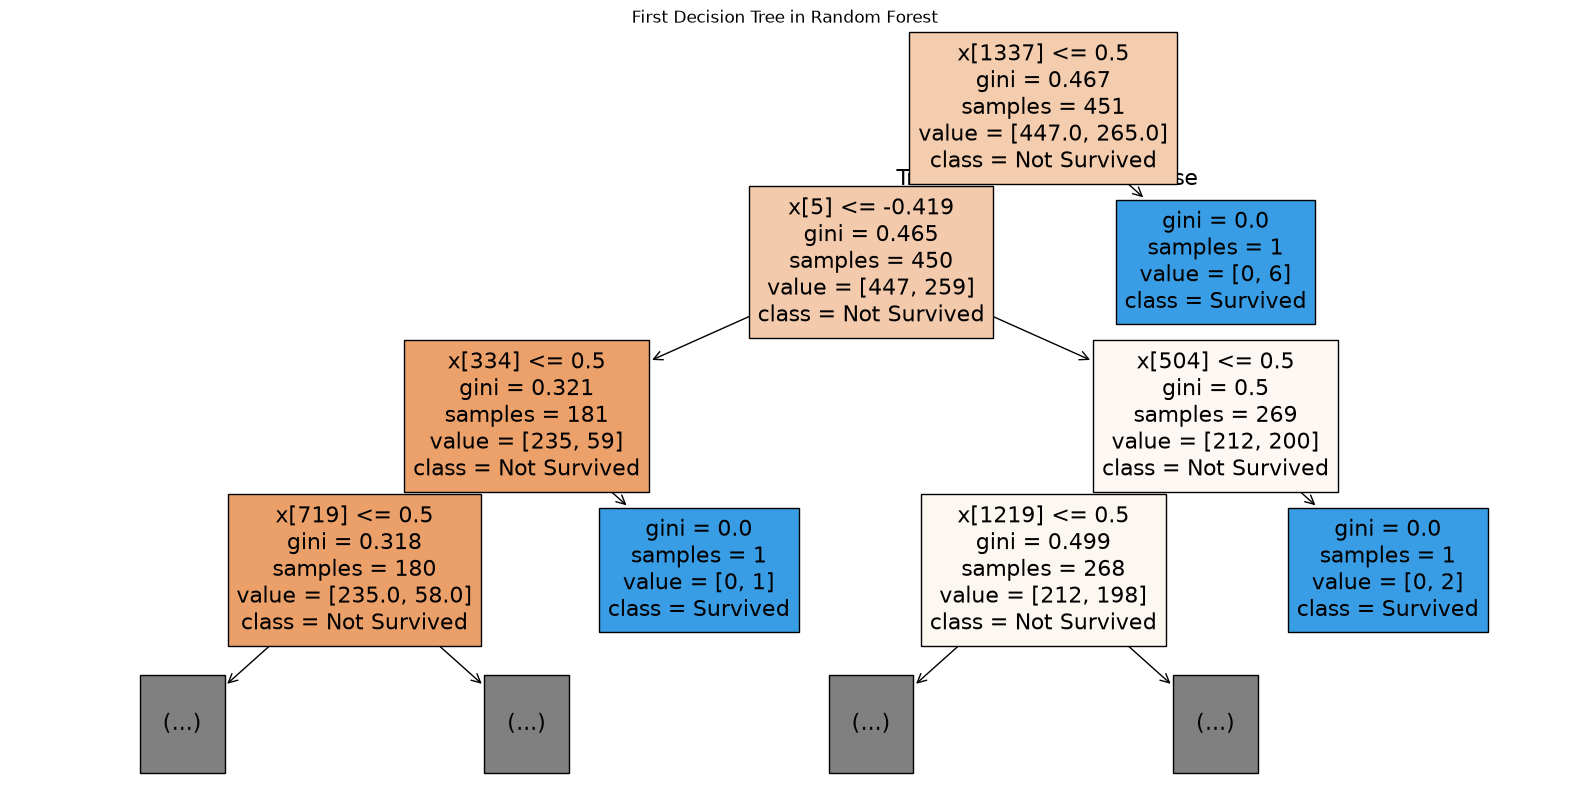

In [109]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

rf = rf_grid.best_estimator_
dt = rf.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    feature_names=None,
    class_names=["Not Survived", "Survived"],
    filled=True,
    max_depth=3
)
plt.title("First Decision Tree in Random Forest")
plt.show()

Explained Variance Ratio: [0.19399514 0.1839103 ]
Total Variance Explained: 0.37790543775451557


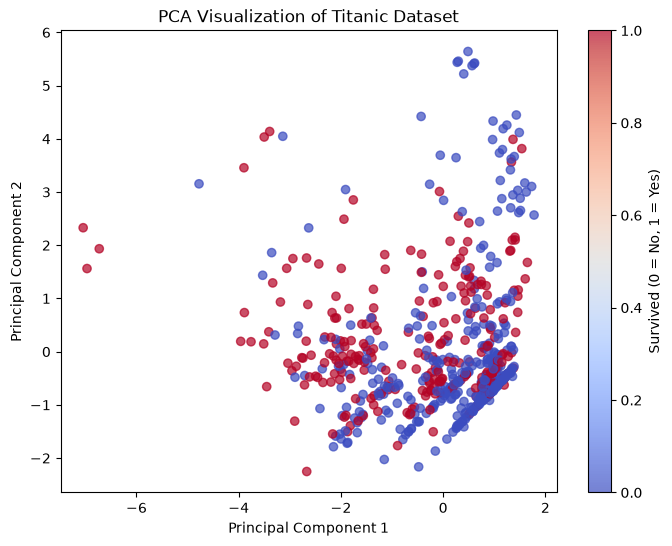

In [115]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:", sum(pca.explained_variance_ratio_))

plt.figure(figsize=(8, 6))
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
            c=y_train, cmap="coolwarm", alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Titanic Dataset")
plt.colorbar(label="Survived (0 = No, 1 = Yes)")
plt.show()

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:", sum(pca.explained_variance_ratio_))

In [ ]:
log = LogisticRegression(max_iter=1000)
log.fit(X_train_pca, y_train)

y_pred = log.predict(X_test_pca)

print("Accuracy:", accuracy_score(y_test, y_pred))